# 09 – Comprendre le modèle de l'intérieur

Au notebook 06, on a utilisé `HistGradientBoostingClassifier` un peu comme une boîte noire : `fit`, `predict_proba`, et ça marche. Ici, on **ouvre la boîte**.

Fil rouge : **Martigues, le 28 juillet 2025**. Il y a bien eu un feu ce jour-là, et le modèle lui donnait environ **45 %** de risque. On va comprendre *d'où sort ce chiffre*.

**Au programme :**
1. la brique de base : **un arbre de décision**, qu'on dessine et qu'on suit à la main ;
2. le **boosting** : comment 300 arbres s'additionnent, avec une version « faite main » en 10 lignes ;
3. ce que le modèle a appris : les **courbes de dépendance partielle** ;
4. expliquer **une** prédiction : un simulateur « et si… ? » et la contribution de chaque variable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import average_precision_score

df = pd.read_csv("../data/processed/features_13.csv", dtype={"code": str}, parse_dates=["jour"])
communes = pd.read_csv("../data/processed/communes_13.csv", dtype={"code": str})
df = df.merge(communes[["code", "nom", "lat", "lon"]], on="code", how="left")
df["annee"] = df["jour"].dt.year

FEATURES = [
    "mois", "jour_annee", "jour_semaine", "week_end",
    "temp_max", "humidite_min", "vent_max", "pluie", "evapo",
    "pluie_7j", "pluie_30j", "evapo_30j", "temp_max_7j", "bilan_hydrique_30j",
    "jours_sans_pluie", "vent_fort",
    "feux_commune_365j", "feux_commune_cumul", "feux_dept_veille",
    "lat", "lon",
]
REGLAGES = dict(learning_rate=0.03, max_iter=300, early_stopping=False,
                max_leaf_nodes=7, min_samples_leaf=1000, random_state=42)

train = df[df["annee"] <= 2020]
valid = df[df["annee"].between(2021, 2022)]
appris = df[df["annee"] <= 2022]          # comme le modèle final du notebook 06

# notre fil rouge
martigues = df[(df["nom"] == "Martigues") & (df["jour"] == "2025-07-28")]
martigues[["nom", "jour", "feu", "temp_max", "vent_max", "evapo", "evapo_30j",
           "bilan_hydrique_30j", "jours_sans_pluie", "feux_commune_365j"]]

,nom,jour,feu,temp_max,vent_max,evapo,evapo_30j,bilan_hydrique_30j,jours_sans_pluie,feux_commune_365j
204411,Martigues,2025-07-28,1,26.5,45.3,8.43,217.55,-176.45,7,23.0


Ce jour-là à Martigues : 26,5 °C seulement, mais **vent à 45 km/h**, une très forte évapotranspiration (8,4 mm dans la journée, 218 mm sur 30 jours → bilan hydrique de −176 mm : végétation desséchée), et une commune qui a déjà connu **23 jours avec feu** dans l'année écoulée.

## Partie 1 – Un arbre de décision

### Leçon 1 – Comment un arbre choisit ses questions
Un arbre pose des questions oui/non (« `evapo_30j` > 151 ? »). Pour choisir chaque question, l'algorithme :
1. essaie **toutes** les variables et **tous** les seuils possibles ;
2. pour chacun, coupe les données en deux groupes ;
3. garde la coupure qui donne les groupes les plus **« purs »** (l'un avec beaucoup de feux, l'autre avec très peu) ;
4. recommence dans chaque groupe, jusqu'à la profondeur maximale.

Personne ne lui dit que la sécheresse compte : il le **découvre** dans les données.

On entraîne un seul petit arbre, limité à **3 niveaux de questions** (donc 8 feuilles au maximum), sur 2016-2020 :

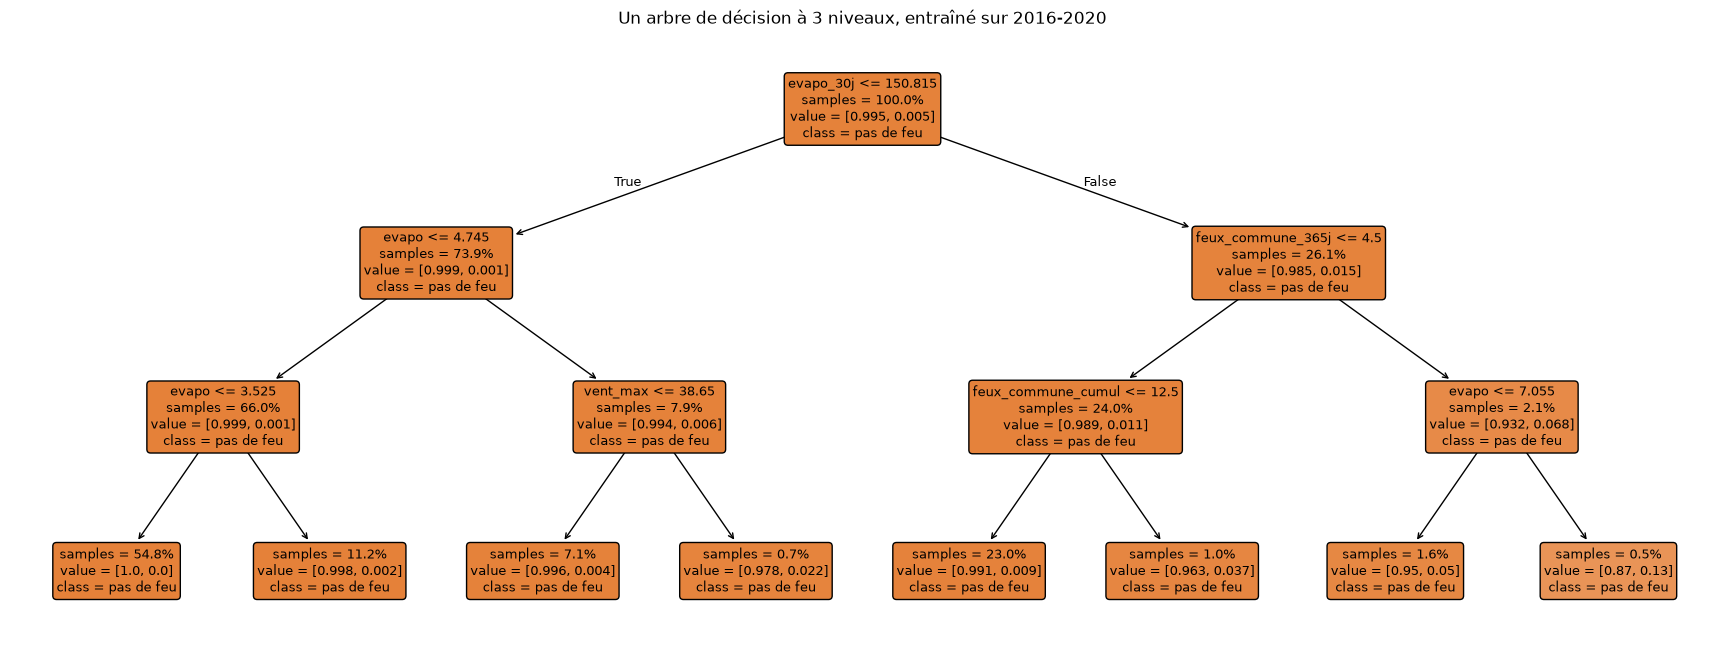

In [2]:
arbre = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1000, random_state=42)
arbre.fit(train[FEATURES], train["feu"])

plt.figure(figsize=(22, 8))
plot_tree(arbre, feature_names=FEATURES, class_names=["pas de feu", "feu"],
          filled=True, proportion=True, impurity=False, rounded=True, fontsize=9)
plt.title("Un arbre de décision à 3 niveaux, entraîné sur 2016-2020")
plt.show()

**Comment lire chaque boîte :**
- la 1ʳᵉ ligne est la **question** (flèche de gauche, `True` = oui ; flèche de droite, `False` = non) ;
- `samples` = la part des lignes qui arrivent dans cette boîte ;
- `value` = [part sans feu, part avec feu] ;
- `class` = la réponse majoritaire.

**Remarque importante :** toutes les boîtes disent `class = pas de feu`, même la plus dangereuse (13 % de feux, donc 87 % sans feu). Si on demandait à l'arbre de répondre seulement oui/non, il dirait **toujours non** ! C'est pour ça qu'avec des événements rares, on utilise la **probabilité** (la part de feux dans la feuille) et non la classe majoritaire : elle permet de **classer** les situations de la moins risquée à la plus risquée.

Un tableau des **feuilles** est plus parlant :

In [3]:
feuille = arbre.apply(train[FEATURES])          # numéro de la feuille où tombe chaque ligne
feuilles = (train.assign(feuille=feuille)
            .groupby("feuille")["feu"].agg(lignes="size", jours_avec_feu="sum", taux="mean")
            .sort_values("taux"))
feuilles["taux"] = (feuilles["taux"] * 100).round(2).astype(str) + " %"
feuilles

,lignes,jours_avec_feu,taux
feuille,,,
3,119130,48,0.04 %
4,24443,56,0.23 %
6,15494,62,0.4 %
10,50010,475,0.95 %
7,1609,35,2.18 %
11,2115,78,3.69 %
13,3568,179,5.02 %
14,1044,136,13.03 %


`arbre.apply(...)` renvoie, pour chaque ligne, le numéro de la feuille où elle atterrit. Le taux de feu va de quelques centièmes de % dans la feuille la plus sûre à plus de 10 % dans la plus dangereuse : l'arbre a bien trié les situations.

### Suivre Martigues dans l'arbre
`decision_path` donne la liste des boîtes traversées. Pour chacune, on lit dans la structure interne de l'arbre (`arbre.tree_`) la variable et le seuil testés :

In [4]:
x = martigues[FEATURES]
chemin = arbre.decision_path(x).indices
structure = arbre.tree_

for noeud in chemin:
    if structure.children_left[noeud] == -1:        # -1 = pas d'enfant → c'est une feuille
        proportion_feu = structure.value[noeud][0][1]
        print(f"→ FEUILLE : {proportion_feu:.1%} de jours avec feu parmi les exemples d'entraînement")
    else:
        variable = FEATURES[structure.feature[noeud]]
        seuil = structure.threshold[noeud]
        valeur = x[variable].iloc[0]
        print(f"{variable} = {valeur:.2f}  {'≤' if valeur <= seuil else '>'} {seuil:.2f}")

evapo_30j = 217.55  > 150.82
feux_commune_365j = 23.00  > 4.50
evapo = 8.43  > 7.06
→ FEUILLE : 13.0% de jours avec feu parmi les exemples d'entraînement


Martigues ce jour-là passe par : végétation desséchée → commune à historique chargé → journée très évaporante → la feuille la plus dangereuse (≈ 13 %), soit plus de 20 fois le risque moyen.

**Limite :** un arbre de 3 niveaux n'a que 8 réponses possibles. Tous les jours qui tombent dans la même feuille reçoivent **exactement** la même probabilité, qu'il y ait du vent ou non (ici, le vent n'est même pas regardé dans cette branche). Pour être plus fin, on pourrait faire un arbre plus profond… mais il apprendrait par cœur (surapprentissage, notebook 06). D'où l'idée du boosting.

## Partie 2 – Le boosting : 300 petits arbres qui se corrigent

### Leçon 2 – Le principe
1. On part d'une prédiction **identique pour tous** : le taux moyen de feu (≈ 0,6 %).
2. Pour chaque ligne, on calcule l'**erreur** = vérité (0 ou 1) − prédiction actuelle. Un jour avec feu prédit à 0,6 % a une grosse erreur positive ; un jour sans feu, une toute petite erreur négative.
3. Un **nouvel arbre** est entraîné, non pas à prédire le feu, mais à **prédire ces erreurs** : *« où est-ce qu'on se trompe encore ? »*
4. On ajoute sa correction **multipliée par un petit facteur** (le `learning_rate`, 0,03 chez nous) : chaque arbre ne fait qu'un petit pas prudent.
5. On recommence : le 2ᵉ arbre corrige ce que le 1ᵉʳ a raté, le 3ᵉ ce que les deux premiers ont raté, etc.

C'est le « **gradient** » de gradient boosting : l'erreur indique dans quelle direction corriger, comme une pente qu'on descend pas à pas.

### Le faire nous-mêmes, en 10 lignes
Pour vraiment comprendre, on code une version **simplifiée** à la main : des arbres de **régression** (`DecisionTreeRegressor`, qui prédit un nombre et non une classe) entraînés sur les erreurs. Compte environ 30 secondes.

In [5]:
X_tr, y_tr = train[FEATURES], train["feu"].values
X_va, y_va = valid[FEATURES], valid["feu"].values

pas = 0.1
pred_tr = np.full(len(X_tr), y_tr.mean())   # étape 1 : tout le monde au taux moyen
pred_va = np.full(len(X_va), y_tr.mean())

suivi = []
for i in range(1, 61):
    erreur = y_tr - pred_tr                                   # étape 2 : les erreurs
    petit_arbre = DecisionTreeRegressor(max_leaf_nodes=7, min_samples_leaf=1000, random_state=42)
    petit_arbre.fit(X_tr, erreur)                             # étape 3 : un arbre qui prédit les erreurs
    pred_tr = pred_tr + pas * petit_arbre.predict(X_tr)       # étape 4 : on corrige un peu
    pred_va = pred_va + pas * petit_arbre.predict(X_va)
    if i in [1, 2, 5, 10, 20, 40, 60]:
        suivi.append({"arbres": i, "PR-AUC validation": round(average_precision_score(y_va, pred_va), 4)})

pd.DataFrame(suivi)

,arbres,PR-AUC validation
0,1,0.0331
1,2,0.0404
2,5,0.0481
3,10,0.0519
4,20,0.0567
5,40,0.0645
6,60,0.0623


Avec **1 seul arbre**, la PR-AUC est modeste (≈ 0,033) ; à chaque arbre ajouté, elle progresse, et dès 5 arbres notre version maison égale la baseline commune × mois (0,048). Elle culmine vers 40 arbres (≈ 0,065) puis **redescend légèrement** : les arbres suivants commencent à corriger du « bruit » propre au train → c'est le début du **surapprentissage**. D'où l'importance de bien choisir le nombre d'arbres et le pas (notebook 06).

**Ce que fait en plus `HistGradientBoostingClassifier` :**
- il ne corrige pas directement des probabilités, mais des **log-odds** (une échelle qui va de −∞ à +∞), puis les reconvertit en probabilité avec une courbe en S (la fonction **sigmoïde**). Ça garantit que la prédiction reste entre 0 et 1, et ça corrige mieux les événements rares ;
- **« Hist »** : il range d'abord chaque variable en 255 tranches (un **histogramme**) au lieu de tester chaque valeur exacte comme seuil → beaucoup plus rapide sur des centaines de milliers de lignes.

### Le vrai modèle, arbre par arbre
`staged_predict_proba` donne la prédiction après 1 arbre, 2 arbres… jusqu'à 300. On compare Martigues le 28 juillet 2025 à deux jours très différents :

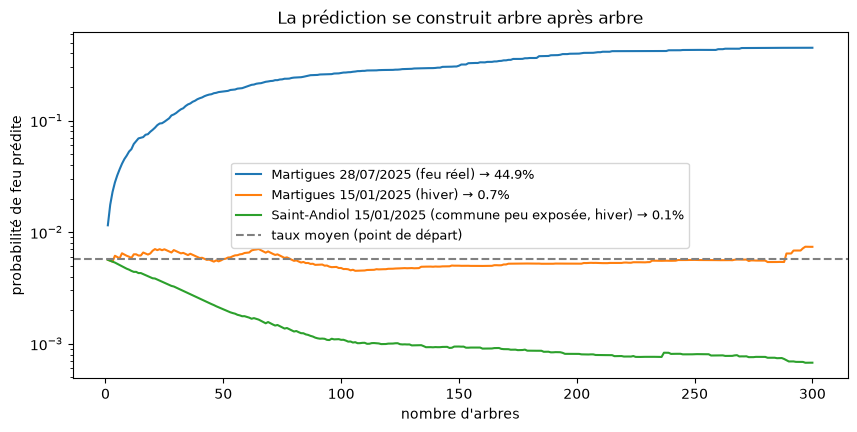

In [6]:
modele = HistGradientBoostingClassifier(**REGLAGES)
modele.fit(appris[FEATURES], appris["feu"])

exemples = {
    "Martigues 28/07/2025 (feu réel)": martigues,
    "Martigues 15/01/2025 (hiver)": df[(df["nom"] == "Martigues") & (df["jour"] == "2025-01-15")],
    "Saint-Andiol 15/01/2025 (commune peu exposée, hiver)": df[(df["nom"] == "Saint-Andiol") & (df["jour"] == "2025-01-15")],
}

plt.figure(figsize=(10, 4.5))
for nom, ligne in exemples.items():
    trajectoire = [p[0, 1] for p in modele.staged_predict_proba(ligne[FEATURES])]
    plt.plot(range(1, len(trajectoire) + 1), trajectoire, label=f"{nom} → {trajectoire[-1]:.1%}")
plt.axhline(appris["feu"].mean(), color="grey", linestyle="--", label="taux moyen (point de départ)")
plt.xlabel("nombre d'arbres")
plt.ylabel("probabilité de feu prédite")
plt.yscale("log")
plt.title("La prédiction se construit arbre après arbre")
plt.legend(fontsize=9)
plt.show()

`plt.yscale("log")` : échelle **logarithmique** sur l'axe vertical, pour voir sur le même graphique des probabilités de 0,01 % et de 45 %.

**Lecture :** les trois courbes partent du même point (le taux moyen, ≈ 0,6 %).
- **Martigues en juillet** : presque chaque arbre ajoute « un peu plus de risque », parce que plusieurs signaux s'additionnent → ≈ 45 %.
- **Saint-Andiol en hiver** (petite commune agricole du nord, rarement touchée) : les arbres font **baisser** le risque jusqu'à moins de 0,1 %.
- **Martigues en hiver** : intéressant ! La saison pousse vers le bas, mais l'historique très chargé de la commune pousse vers le haut : les arbres se compensent et la prédiction reste proche de la moyenne (≈ 0,7 %).

Au bout du compte, le modèle n'est **rien d'autre que 300 arbres × 7 feuilles = 2 100 petites règles pondérées**, qu'on additionne.

## Partie 3 – Ce que le modèle a appris : la dépendance partielle

Personne ne peut lire 2 100 règles. On interroge donc le modèle de l'extérieur.

### Leçon 3 – La dépendance partielle
Question : *« si je fais varier **une seule** variable, toutes les autres restant comme dans la réalité, comment évolue le risque prédit en moyenne ? »*
Concrètement, pour la valeur « bilan hydrique = −150 », on **force** cette valeur dans des milliers de lignes réelles, on prédit, on fait la moyenne ; puis on recommence pour −140, −130… et on trace la courbe.

On le fait sur un échantillon de 4 000 jours pris **sur toute l'année** 2016-2022. Compte environ 30 secondes.

`.astype(float)` convertit toutes les colonnes en nombres décimaux : l'outil refuse les colonnes d'entiers (comme `jours_sans_pluie`), car il doit pouvoir tester des valeurs intermédiaires.

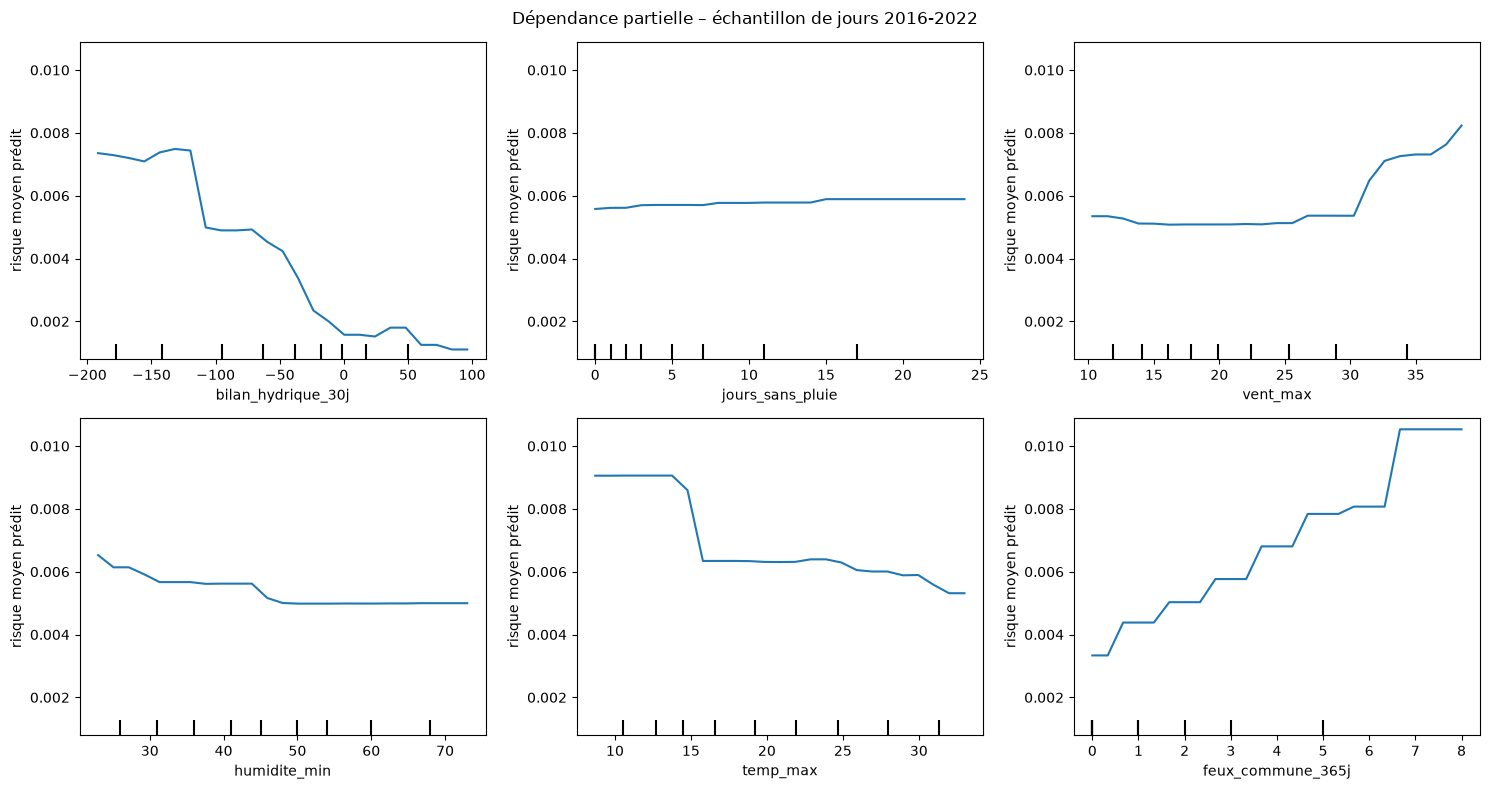

In [7]:
echantillon = appris.sample(4000, random_state=42)[FEATURES].astype(float)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
PartialDependenceDisplay.from_estimator(
    modele, echantillon,
    features=["bilan_hydrique_30j", "jours_sans_pluie", "vent_max",
              "humidite_min", "temp_max", "feux_commune_365j"],
    response_method="predict_proba", method="brute", grid_resolution=25,
    ax=ax.ravel(),
)
for a in ax.ravel():
    a.set_ylabel("risque moyen prédit")
plt.suptitle("Dépendance partielle – échantillon de jours 2016-2022")
plt.tight_layout()
plt.show()

Les petits traits en bas de chaque graphique montrent où se trouvent les données réelles : là où il y en a peu, la courbe est moins fiable.

**Ce qu'on lit (vérifie sur tes courbes) :**
- **bilan hydrique** : le risque est multiplié par environ 6 entre une végétation bien arrosée (bilan positif) et desséchée (en dessous de −100 mm) ; au-delà, il plafonne ;
- **vent** : plat jusqu'à ~28 km/h, puis il grimpe nettement (mistral) ;
- **humidité minimale** : plus l'air est sec, plus le risque est élevé ;
- **historique de la commune** : l'effet le plus fort – de 0 à 7 jours avec feu dans l'année, le risque est multiplié par 3 ;
- **jours sans pluie** : presque plat ! Ça ne veut pas dire que la sécheresse ne compte pas : le **bilan hydrique** porte déjà cette information, et le modèle s'en sert à la place (variables corrélées, comme au notebook 06) ;
- **température** : la courbe **descend**, ce qui semble absurde. C'est un artefact : forcer 33 °C dans une ligne de janvier (avec l'évapotranspiration et l'humidité de janvier) crée une situation qui n'existe pas. L'effet de la chaleur passe en réalité par l'**évapotranspiration** et l'**humidité**, qui en dépendent.

Les courbes sont **en escalier** : c'est la signature des arbres, qui raisonnent par seuils.

⚠️ **Le piège, illustré par la température :** « toutes choses égales par ailleurs » est parfois irréaliste quand les variables sont **corrélées** (chaleur, évapotranspiration, humidité, saison…). Une courbe de dépendance partielle décrit **comment le modèle réagit**, pas forcément **comment le monde fonctionne**. On la lit avec du bon sens physique.

> Pourquoi pas seulement des jours d'été ? Essaie : sur un échantillon de juillet-août, la courbe du bilan hydrique est plate – en été, la végétation est **toujours** sèche, donc cette variable ne fait plus la différence entre deux jours d'été. C'est le **vent** et l'**historique de la commune** qui départagent alors.

## Partie 4 – Expliquer une prédiction

### Un simulateur « et si… ? »
On reprend la ligne de Martigues et on modifie une ou deux variables pour voir la réaction du modèle. On écrit une petite fonction ; `**changements` permet de lui passer autant de modifications qu'on veut, sous la forme `variable=valeur`.

In [8]:
def et_si(**changements):
    ligne = martigues[FEATURES].copy()
    for variable, valeur in changements.items():
        ligne[variable] = valeur
    return modele.predict_proba(ligne)[0, 1]

scenarios = {
    "la réalité": {},
    "vent faible (15 km/h)": {"vent_max": 15, "vent_fort": 0},
    "commune sans feu dans l'année": {"feux_commune_365j": 0},
    "vent faible ET commune sans historique": {"vent_max": 15, "vent_fort": 0, "feux_commune_365j": 0},
    "végétation moins sèche (bilan −60 mm)": {"bilan_hydrique_30j": -60, "evapo_30j": 120},
    "un dimanche": {"jour_semaine": 6, "week_end": 1},
}
pd.DataFrame({"risque prédit": {nom: f"{et_si(**chg):.1%}" for nom, chg in scenarios.items()}})

,risque prédit
la réalité,44.9%
vent faible (15 km/h),25.6%
commune sans feu dans l'année,11.3%
vent faible ET commune sans historique,5.8%
végétation moins sèche (bilan −60 mm),11.9%
un dimanche,41.0%


On voit **quels leviers** comptent pour ce jour-là. Note que les effets ne s'additionnent pas simplement : le vent pèse plus quand la végétation est sèche, et inversement. C'est justement ce que les arbres savent capturer – et ce qu'une règle simple (la baseline) ne sait pas faire.

**À toi de jouer :** ajoute un scénario « canicule » (`temp_max=38`, `humidite_min=15`) et un scénario « en plein hiver » (`mois=1`, `jour_annee=28`). Lequel fait le plus bouger le risque ?

### Quelle variable a « poussé » la prédiction ?
Dernière méthode, simple et parlante : pour chaque variable, on la **remplace par sa valeur typique d'un jour d'été** (la médiane de juillet-août), toutes les autres restant celles du 28 juillet, et on regarde de combien le risque **baisse**. Une grosse baisse = cette variable expliquait une bonne partie du risque ce jour-là.

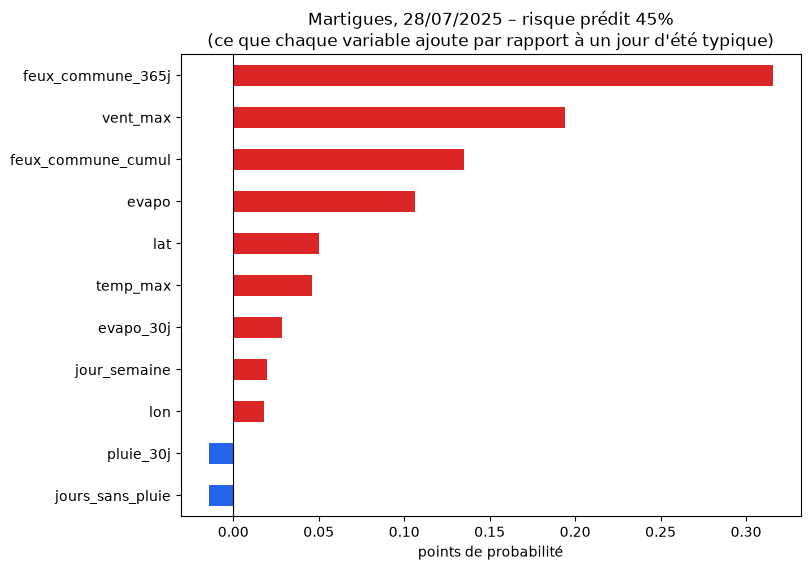

In [9]:
typique = appris[appris["mois"].isin([7, 8])][FEATURES].median()
risque_reel = et_si()

contributions = {}
for variable in FEATURES:
    contributions[variable] = risque_reel - et_si(**{variable: typique[variable]})

contributions = pd.Series(contributions).sort_values()
contributions[contributions.abs() > 0.005].plot(
    kind="barh", figsize=(8, 6), color=["#2563eb" if v < 0 else "#dc2626" for v in contributions[contributions.abs() > 0.005]],
    title=f"Martigues, 28/07/2025 – risque prédit {risque_reel:.0%}\n(ce que chaque variable ajoute par rapport à un jour d'été typique)")
plt.xlabel("points de probabilité")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

- en **rouge**, les variables qui **augmentaient** le risque ce jour-là par rapport à un jour d'été typique ;
- en **bleu**, celles qui le **diminuaient**.

Pour Martigues, l'historique chargé de la commune et le vent dominent, suivis par la sécheresse du jour. C'est exactement le chemin qu'on avait suivi dans l'arbre de la partie 1 – mais nuancé par les 300 arbres.

> Pour aller plus loin : la méthode de référence s'appelle **SHAP** (bibliothèque `shap`). Elle répartit la prédiction entre les variables de façon rigoureuse (les contributions s'additionnent exactement). Notre méthode « remplacer par une valeur typique » en est une version simplifiée.

## Récap du notebook

1. **Un arbre** choisit lui-même ses questions en cherchant les coupures qui séparent le mieux feux et non-feux ; il est lisible mais grossier.
2. **Le boosting** additionne des centaines de petits arbres, chacun entraîné sur les **erreurs** des précédents, avec un petit pas (`learning_rate`). Notre version maison en 10 lignes bat déjà la baseline.
3. Le vrai modèle = **2 100 règles pondérées** additionnées en log-odds, puis converties en probabilité.
4. **Dépendance partielle** : comment le risque évolue avec une variable (sécheresse, vent, historique…), en escalier.
5. **Expliquer une prédiction** : simulateur « et si » et contributions par rapport à un jour typique.